Task 3 compares model performance for the task of predicting a 72h ED revisit at ED discharge (hospitalized stays are excluded).

# Set-Up

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import polars as pl
import tqdm
from time import perf_counter
import importlib
import logging
import mlflow
from mlflow import MlflowClient
from pathlib import Path
from pprint import pprint
from matplotlib import pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix

from models.config import Config, DEFAULT_FEATURES
from models.data_prep import DataPartition
from models import plots, metrics

# quiet mlflow warnings
logging.getLogger("mlflow").setLevel(logging.ERROR)

# set path to local data
path = Path().resolve().parent / "data"

## Environment Parameters

In [3]:
TARGET = "outcome_ed_revisit_3d"

# task 3 features: triage vitals are dropped (keeping pain and acuity) and replaced by the last ED
# vitals, ED length of stay and medication counts -- same order as the original notebook
FEATURES = {
    **DEFAULT_FEATURES,
    "triage": ["triage_pain", "triage_acuity"],
    "ed": [
        "ed_temperature_last", "ed_heartrate_last", "ed_resprate_last", "ed_o2sat_last",
        "ed_sbp_last", "ed_dbp_last", "ed_los", "n_med", "n_medrecon",
    ],
}

### Helper Functions

In [4]:
## mlflow helper functions for model management ##

def get_model_uri_from_runs(experiment_id: str, run_name: str, artifact_path: str = "model") -> str:
    """Return the `runs:/` URI of the most recent run with the given name."""
    runs = mlflow.search_runs(
        experiment_ids=[experiment_id],
        filter_string=f"tags.mlflow.runName = '{run_name}'",
        order_by=["attributes.start_time DESC"],
        max_results=1,
    )
    if runs.empty:
        raise RuntimeError(f"No MLflow run found with name {run_name!r}.")
    return f"runs:/{runs.iloc[0]['run_id']}/{artifact_path}"


def _flavor_module(flavor: str):
    """Return the `mlflow.<flavor>` module (e.g. `mlflow.xgboost`)."""
    return importlib.import_module(f"mlflow.{flavor}")


def log_model(model: object, artifact_path: str = "model", flavor: str | None = None, **kwargs) -> str:
    """Log a model to the active MLflow run and return its `runs:/` URI.
    Inherits mlflow model flavor from `flavor`, inferring from the model's top-level package if omitted.
    Extra `kwargs` go to the flavor's `log_model` (e.g. `skops_trusted_types` for sklearn).
    """
    active_run = mlflow.active_run()
    if active_run is None:
        raise RuntimeError("Start an MLflow run before logging a model.")

    flavor = flavor or type(model).__module__.split(".")[0]
    try:
        flavor_module = _flavor_module(flavor)
    except ImportError as e:
        raise ValueError(f"No MLflow flavor {flavor!r}; pass `flavor=` explicitly.") from e
    flavor_module.log_model(model, artifact_path=artifact_path, **kwargs)
    return f"runs:/{active_run.info.run_id}/{artifact_path}"


def register_model_version(model_uri: str, model_name: str, alias: str | None = None):
    """Register a model URI as a new version of `model_name`."""
    version = mlflow.register_model(model_uri, model_name)
    if alias is not None:
        # alias APIs live on the client, not the top-level `mlflow` module
        MlflowClient().set_registered_model_alias(model_name, alias, version.version)
    return version


def load_registered_model(model_name: str, alias: str | None = None):
    """Load a registered scikit-learn model by name."""
    client = MlflowClient()
    try:
        if alias is not None:
            version = client.get_model_version_by_alias(model_name, alias)
        else:
            versions = client.search_model_versions(f"name = '{model_name}'")
            if not versions:
                raise ValueError(f"No versions found for registered model {model_name!r}.")
            version = max(versions, key=lambda v: int(v.version))
    except mlflow.exceptions.MlflowException as e:
        raise ValueError(f"Could not resolve {model_name!r} (alias={alias!r}): {e}") from e

    print(f"Loading {model_name!r} version {version.version}" + (f" (alias {alias!r})" if alias else ""))
    uri = f"models:/{model_name}/{version.version}"
    flavors = set(mlflow.models.get_model_info(uri).flavors) - {"python_function"}
    if not flavors:
        return mlflow.pyfunc.load_model(uri)
    return _flavor_module(sorted(flavors)[0]).load_model(uri)

# Define Data

In [5]:
train_df = pl.read_parquet(path / "outputs/train.parquet")
test_df = pl.read_parquet(path / "outputs/test.parquet")
# task-specific filter: ED-discharged patients only, i.e. exclude hospitalized cases
train_df = train_df.filter(~pl.col("outcome_hospitalization"))
test_df = test_df.filter(~pl.col("outcome_hospitalization"))
print(f"train_df shape: {train_df.shape}")
print(f"test_df shape:  {test_df.shape}")

train_df shape: (185985, 124)
test_df shape:  (46476, 124)


In [6]:
# binarize `gender` using LabelEncoder -- matches original approach
le = LabelEncoder()

train_df = train_df.with_columns(pl.Series("gender", le.fit_transform(train_df["gender"].to_numpy())))
test_df = test_df.with_columns(pl.Series("gender", le.transform(test_df["gender"].to_numpy())))

# ED length of stay: duration -> minutes
# (the original used pandas' `.dt.seconds`, which drops whole days; total minutes keeps stays > 24h intact)
train_df = train_df.with_columns(pl.col("ed_los").dt.total_minutes().cast(pl.Float64))
test_df = test_df.with_columns(pl.col("ed_los").dt.total_minutes().cast(pl.Float64))

In [7]:
# use DataPartition objects for convenience -- use default features from default config
train = DataPartition(train_df, target=TARGET, config=Config(features=FEATURES))
test = DataPartition(test_df, target=TARGET, config=Config(features=FEATURES))

In [8]:
# Eval target class ratio
train_rate = train.y.sum().item() / train.y.shape[0]
test_rate = test.y.sum().item() / test.y.shape[0]
print(f"Training Target Class Distribution: Rate: {train_rate:,.4f}  |  Ratio: {train_rate / (1 - train_rate):,.4f}")
print(f"Testing Target Class Distribution:  Rate: {test_rate:,.4f}  |  Ratio: {test_rate / (1 - test_rate):,.4f}")

Training Target Class Distribution: Rate: 0.0457  |  Ratio: 0.0479
Testing Target Class Distribution:  Rate: 0.0443  |  Ratio: 0.0463


# Model Benchmarks

In [9]:
# create mlflow experiment for model telemetry and logging
mlflow.set_experiment("mimic4ed-benchmarks")
experiment = mlflow.get_experiment_by_name("mimic4ed-benchmarks")

## Logistic Regression

In [10]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=42, max_iter=100)

# log with mlflow
with mlflow.start_run(run_name="logistic-regression-task3"):
    mlflow.log_params(lr.get_params())

    start_time = perf_counter()
    lr.fit(train.X, train.y)
    fit_time_seconds = perf_counter() - start_time
    mlflow.log_metric("fit_time_seconds", fit_time_seconds)

    y_true = test.y
    y_pred = lr.predict(test.X)
    y_prob = lr.predict_proba(test.X)[:, 1]

    lr_metrics = metrics.BasicMetrics(
        y_true=y_true,
        y_pred=y_pred,
        y_prob=y_prob,
        cm=confusion_matrix(y_true, y_pred, labels=lr.classes_).ravel(),
    )

    mlflow.log_metrics(lr_metrics.dict)
    model_uri = log_model(lr, artifact_path="model", flavor="sklearn")

print(f"Training Time: {fit_time_seconds:,.2f}")
pprint(lr_metrics.dict)

c:\Users\benak\repos\mimic4ed-task\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Time: 5.17
{'accuracy': 0.9562569928565281,
 'average_precision': 0.15341369751920705,
 'f1': 0.08050655811849841,
 'fn': 1969.0,
 'fp': 64.0,
 'precision': 0.5816993464052288,
 'recall': 0.043245869776482024,
 'roc_auc': 0.682271113484535,
 'specificity': 0.9985591426899005,
 'tn': 44354.0,
 'tp': 89.0}


Registered model 'logistic-regression-task3' already exists. Creating a new version of this model...
Created version '3' of model 'logistic-regression-task3'.


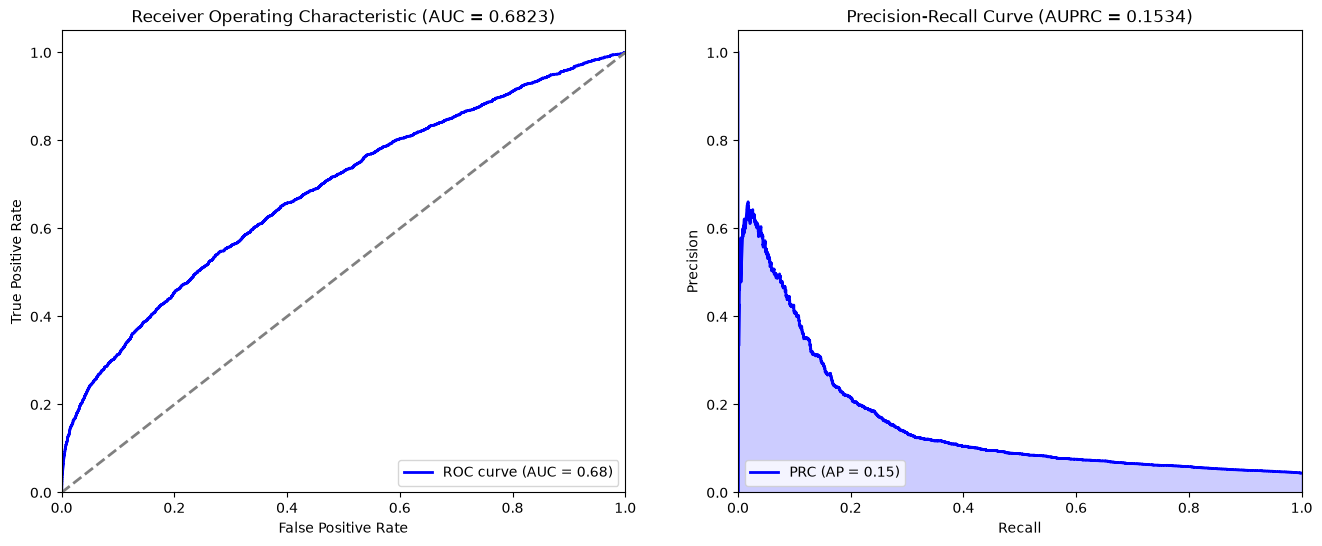

In [11]:
# register the model
lr_version = register_model_version(model_uri, model_name="logistic-regression-task3", alias="basic")

# make plots
plots.plot_roc_prc(test.y, lr.predict_proba(test.X)[:, 1])

## Random Forest

In [12]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=42)


# log with mlflow
with mlflow.start_run(run_name="random-forest-task3"):
    mlflow.log_params(rf.get_params())

    start_time = perf_counter()
    rf.fit(train.X, train.y)
    fit_time_seconds = perf_counter() - start_time
    mlflow.log_metric("fit_time_seconds", fit_time_seconds)

    y_true = test.y
    y_pred = rf.predict(test.X)
    y_prob = rf.predict_proba(test.X)[:, 1]

    rf_metrics = metrics.BasicMetrics(
        y_true=y_true,
        y_pred=y_pred,
        y_prob=y_prob,
        cm=confusion_matrix(y_true, y_pred, labels=rf.classes_).ravel(),
    )

    mlflow.log_metrics(rf_metrics.dict)

    # mlflow saves with skops by default - skops needs trusted types to load safely
    # and Tree isn't one of its trusted types by default (ugh)
    model_uri = log_model(
        rf, artifact_path="model", flavor="sklearn",
        skops_trusted_types=["sklearn.tree._tree.Tree"],
    )

print(f"Training Time: {fit_time_seconds:,.2f}")
pprint(rf_metrics.dict)

Training Time: 38.58
{'accuracy': 0.9562139598932783,
 'average_precision': 0.14469489766472624,
 'f1': 0.06779661016949153,
 'fn': 1984.0,
 'fp': 51.0,
 'precision': 0.592,
 'recall': 0.03595724003887269,
 'roc_auc': 0.6616600561736565,
 'specificity': 0.9988518168310144,
 'tn': 44367.0,
 'tp': 74.0}


Registered model 'random-forest-task3' already exists. Creating a new version of this model...
Created version '3' of model 'random-forest-task3'.


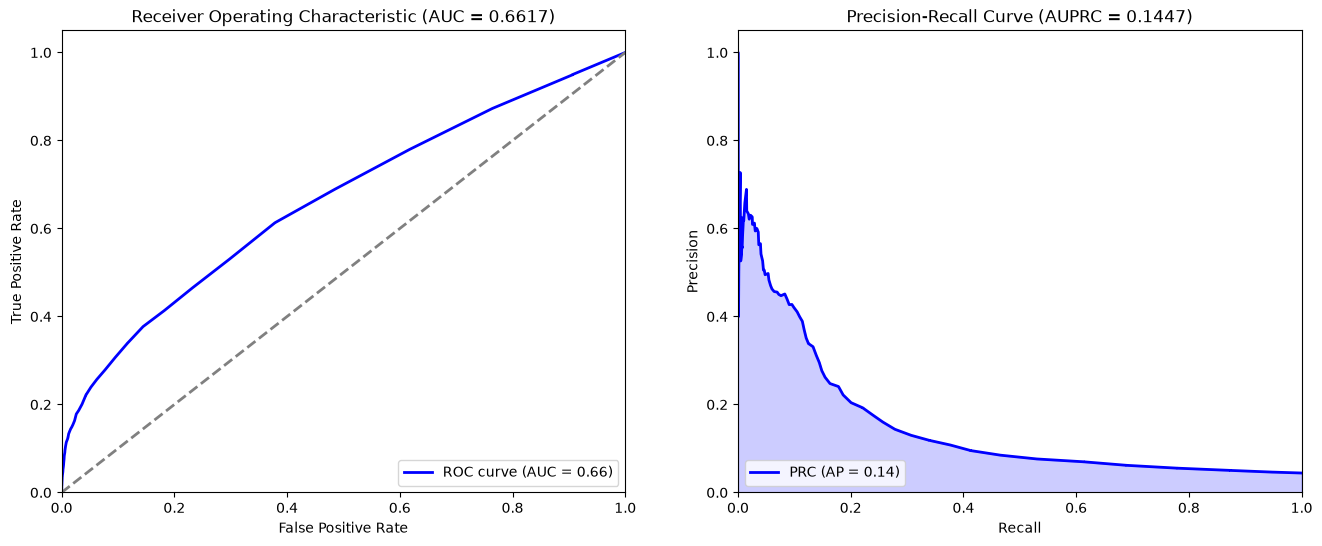

In [13]:
# register model with mlflow
rf_version = register_model_version(model_uri, model_name="random-forest-task3", alias="basic")

# plot ROC-PRC
plots.plot_roc_prc(test.y, rf.predict_proba(test.X)[:, 1])

## XGBoost

In [14]:
from xgboost import XGBClassifier
xgb = XGBClassifier(random_state=42)


# log with mlflow
with mlflow.start_run(run_name="xgboost-task3"):
    mlflow.log_params(xgb.get_params())

    start_time = perf_counter()
    xgb.fit(train.X, train.y)
    fit_time_seconds = perf_counter() - start_time
    mlflow.log_metric("fit_time_seconds", fit_time_seconds)

    y_true = test.y
    y_pred = xgb.predict(test.X)
    y_prob = xgb.predict_proba(test.X)[:, 1]

    xgb_metrics = metrics.BasicMetrics(
        y_true=y_true,
        y_pred=y_pred,
        y_prob=y_prob,
        cm=confusion_matrix(y_true, y_pred, labels=xgb.classes_).ravel(),
    )

    mlflow.log_metrics(xgb_metrics.dict)

    # mlflow saves with skops by default - skops needs trusted types to load safely
    model_uri = log_model(
        xgb, artifact_path="model", flavor="sklearn",
        skops_trusted_types=['xgboost.core.Booster', 'xgboost.sklearn.XGBClassifier'],
    )

print(f"Training Time: {fit_time_seconds:,.2f}")
pprint(xgb_metrics.dict)

Training Time: 1.08
{'accuracy': 0.955417850073156,
 'average_precision': 0.1438978392877472,
 'f1': 0.08963093145869948,
 'fn': 1956.0,
 'fp': 116.0,
 'precision': 0.46788990825688076,
 'recall': 0.04956268221574344,
 'roc_auc': 0.6800467560997627,
 'specificity': 0.9973884461254446,
 'tn': 44302.0,
 'tp': 102.0}


Registered model 'xgboost-task3' already exists. Creating a new version of this model...
Created version '3' of model 'xgboost-task3'.


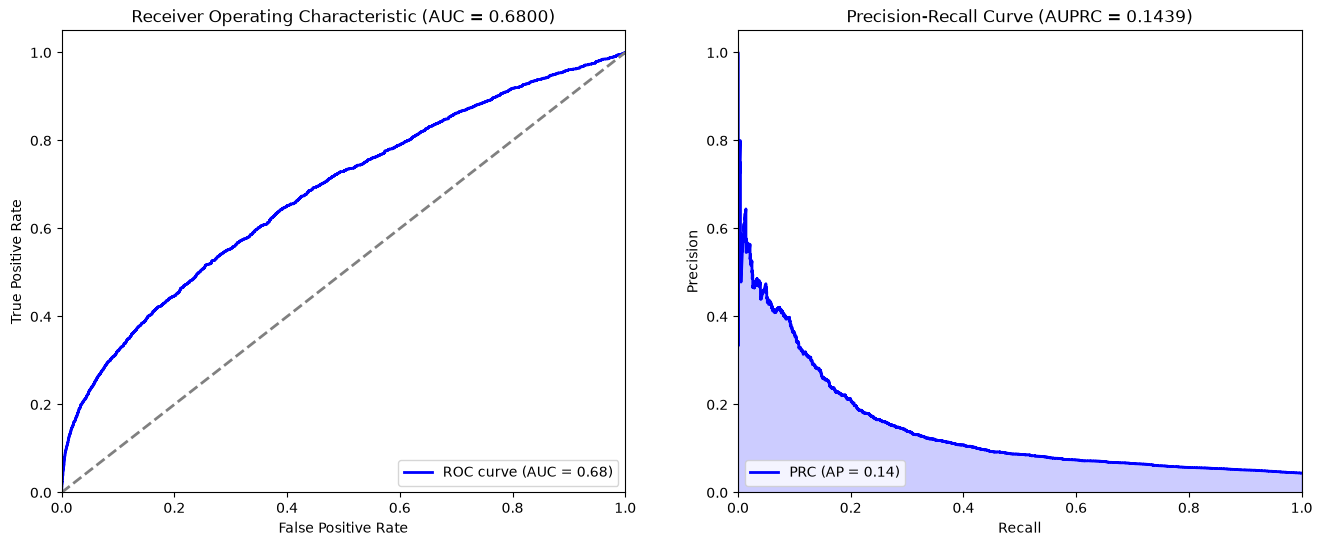

In [15]:
# register model with mlflow
xgb_version = register_model_version(model_uri, model_name="xgboost-task3", alias="basic")

# plot ROC-PRC
plots.plot_roc_prc(test.y, xgb.predict_proba(test.X)[:, 1])

## MLP

In [16]:
import copy
import torch
import torch.nn as nn

# simple feedforward MLP mirroring original notebooks
class MLP(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, output_dim: int, n_layers: int = 2):
        assert n_layers >= 1, "MLP must have at least one hidden layer"
        super(MLP, self).__init__()
        self.n_layers = n_layers
        self.hidden_dim = hidden_dim
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.classifier = nn.Linear(hidden_dim, output_dim)
        self.hidden_layers = nn.Sequential(*[
            layer
            for _ in range(n_layers - 1)
            for layer in (nn.Linear(hidden_dim, hidden_dim), nn.ReLU())
        ])
        
    def forward(self, x):
        x = self.fc1(x)
        x = self.hidden_layers(x)
        x = self.classifier(x)
        return x

In [17]:
# set-up data for MLP training
from torch.utils.data import DataLoader, TensorDataset

def create_dataset(X: np.ndarray, y: np.ndarray) -> TensorDataset:
    return TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32))

def create_dataloader(X: np.ndarray, y: np.ndarray, batch_size: int = 32, shuffle: bool = True) -> DataLoader:
    dataset = create_dataset(X, y)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


train_dl = create_dataloader(train.X, train.y, batch_size=256, shuffle=True)
test_dl = create_dataloader(test.X, test.y, batch_size=256, shuffle=False)


def evaluate(model: MLP, dataloader: DataLoader, criterion: nn.Module = nn.BCEWithLogitsLoss()) -> metrics.BasicMetrics:
    """Helper for evaluating the model on a given dataloader."""
    was_training = True if model.training else False
    model.eval()  # ensure eval mode (not strictly necessary for this MLp but good practice)
    device = next(model.parameters()).device
    all_preds, all_probs, all_targets = [], [], []
    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            logits = model(X_batch.to(device))
            probs = torch.sigmoid(logits).cpu()
            preds = (probs > 0.5).float()  # deterministic (low-temp) classification
            all_preds.append(preds)
            all_targets.append(y_batch)
            all_probs.append(probs)
    all_preds = torch.cat(all_preds)
    all_targets = torch.cat(all_targets)
    all_probs = torch.cat(all_probs)
    if was_training:
        model.train()  # restore original training mode if it was training before evaluation
    res = metrics.BasicMetrics(y_true=all_targets, y_pred=all_preds, y_prob=all_probs, 
                               cm=confusion_matrix(all_targets, all_preds))
    # add loss
    res.loss = criterion(torch.logit(all_probs).squeeze(), all_targets)
    return res


def train_mlp(model: MLP, train_loader: DataLoader, test_loader: DataLoader, optimizer: torch.optim.Optimizer, 
          criterion: nn.Module = nn.BCEWithLogitsLoss(), epochs: int = 10, run_name: str | None = None):
    """Train the model for a specified number of epochs."""
    
    device = next(model.parameters()).device
    model.train()
    # track progress with tqdm
    pbar = tqdm.tqdm(total=epochs * len(train_loader), desc="Training", unit="step")
    start_time = perf_counter()
    with mlflow.start_run(run_name=run_name), pbar:
        mlflow.log_params({
            "epochs": epochs,
            "batch_size": train_loader.batch_size,
            "optimizer": optimizer.__class__.__name__,
            "criterion": criterion.__class__.__name__,
            "n_layers": model.n_layers,
            "hidden_dim": model.hidden_dim,
        })
        for epoch in range(epochs):
            total_loss = 0.0
            for X_batch, y_batch in train_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                optimizer.zero_grad()
                logits = model(X_batch)
                loss = criterion(logits.squeeze(), y_batch)
                total_loss += loss.item() * X_batch.size(0)
                loss.backward()
                optimizer.step()
                pbar.update(1)

            # log metrics at the end of each epoch
            train_metrics = evaluate(model, train_loader)
            mlflow.log_metrics({"train_" + k: v for k, v in train_metrics.to_dict().items()}, step=epoch)

            test_metrics = evaluate(model, test_loader)
            mlflow.log_metrics({"test_" + k: v for k, v in test_metrics.to_dict().items()}, step=epoch)

        fit_time_seconds = perf_counter() - start_time
        mlflow.log_metric("fit_time_seconds", fit_time_seconds)

        # log model at the end of training
        # log a CPU copy with pickle serialization (the default 'pt2' needs an input_example)
        model_uri = log_model(
            copy.deepcopy(model).cpu(), artifact_path="model", flavor="pytorch",
            serialization_format="pickle",
        )

    return model_uri

In [18]:
mlp = MLP(input_dim=train.X.shape[1], hidden_dim=64, n_layers=2, output_dim=1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mlp = mlp.to(device)
optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

mlp_model_uri = train_mlp(mlp, train_dl, test_dl, optimizer, criterion, epochs=20, run_name="mlp-task3")

Training: 100%|██████████| 14540/14540 [02:21<00:00, 102.58step/s]


Registered model 'mlp-task3' already exists. Creating a new version of this model...
Created version '3' of model 'mlp-task3'.


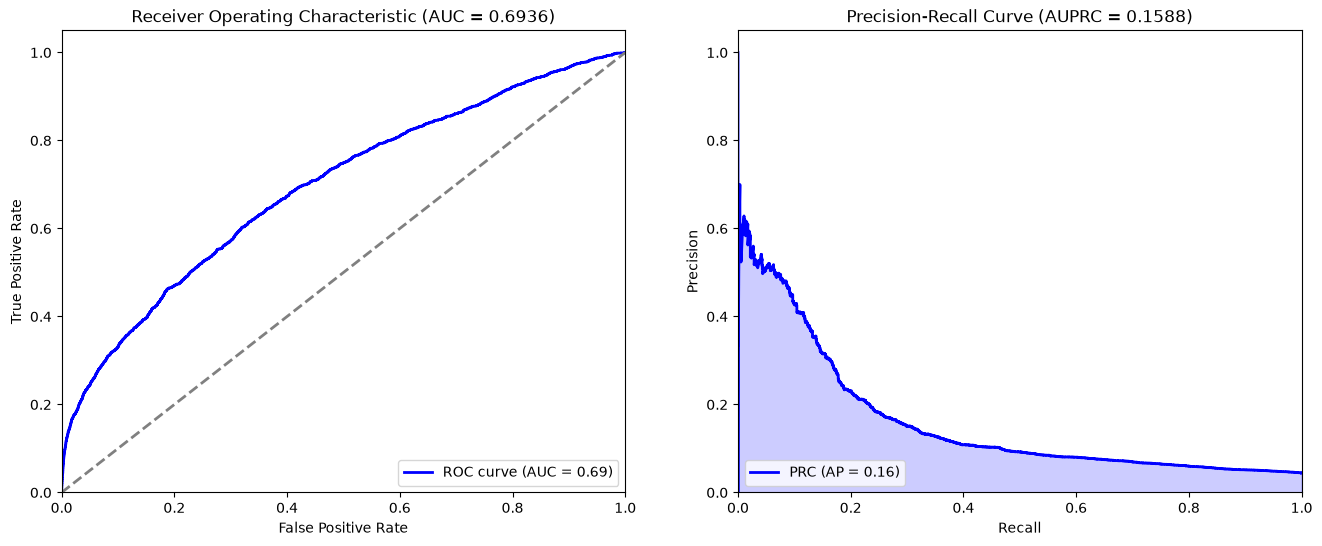

In [19]:
# register model with mlflow
mlp_version = register_model_version(mlp_model_uri, model_name="mlp-task3", alias="basic")

# plot ROC-PRC
plots.plot_roc_prc(
    test.y, 
    torch.sigmoid(
        mlp(torch.tensor(test.X, dtype=torch.float32).to(device))
    ).to('cpu')
    .detach().numpy()
)

# Med2Vec

**NOTE:** Full-disclosure, this portion is primarily authored by Claude. As were `med2vec.py` and `convert_keras_med2vec.py`\
Porting from Keras and running from pretrained hit snags, described below, so we implement a small training loop on the Med2Vec v10 model implemented in PyTorch.

ICD-code embedding model from the original benchmark: embed and sum each stay's prior ICD codes, then combine with the tabular features in a small MLP. The original Keras model is ported to PyTorch in `models.med2vec`, and the three pretrained Keras checkpoints were converted once to `.npz` weights in `data/models/` (see `models/convert_keras_med2vec.py`).

In [20]:
from models import med2vec

VERSION = "v10"

# per-stay ICD code indices (aligned with the train / test rows) and the code -> index map
icd_df = pl.read_parquet(path / f"outputs/icd_list_dataset_{VERSION}.parquet")
encode_map = pl.read_parquet(path / f"outputs/icd_encode_map_{VERSION}.parquet")


def icd_lists_for(df: pl.DataFrame) -> list[list[int]]:
    """ICD index lists for each row of `df`, in row order (empty list when a stay has no history)."""
    joined = (
        df.select("stay_id")
        .join(
            icd_df.select("stay_id", "icd_encoded_list"),
            on="stay_id", how="left", maintain_order="left"
        )
    )
    return [x or [] for x in joined["icd_encoded_list"].to_list()]


train_icd = icd_lists_for(train.df)
test_icd = icd_lists_for(test.df)
print(f"ICD vocabulary in our encoding: {encode_map.height:,} codes | "
      f"max list length (train): {max(map(len, train_icd))}")

ICD vocabulary in our encoding: 14,953 codes | max list length (train): 335


## Train from scratch

This is the original notebook's default path (`load_model = None`): same architecture and training recipe (Adam, lr 1e-3 with the legacy per-step `decay=0.01`, batch size 200), on our own ICD encoding. One deliberate deviation: the original weighted positives by pos/neg, which *down*-weights the minority class and collapses predictions towards 0 on imbalanced tasks, so we use neg/pos. Weights are initialised like Keras (small uniform embeddings, Glorot kernels), on our own ICD encoding. The original trained for 100 epochs; `EPOCHS` is kept small here so the section is quick to run.

In [21]:
import copy
import torch.nn.functional as F
from sklearn.preprocessing import StandardScaler

# standardise inputs for Med2Vec: the raw features span very different scales (counts, minutes, vitals),
# and unscaled they can blow up early training, sometimes collapsing to a constant output
# (the original did not scale)
scaler = StandardScaler().fit(train.X)
X_train_m2v, X_test_m2v = scaler.transform(train.X), scaler.transform(test.X)

EPOCHS = 5          # original: 100
BATCH_SIZE = 200    # matches the original, and the padding-dependent behaviour of the embedding sum
LR, DECAY = 1e-3, 0.01

class_ratio = (1 - train.y).sum() / train.y.sum()   # positive-class weight = neg/pos (negatives get 1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def train_med2vec(model: med2vec.Med2Vec, run_name: str = "med2vec-task3",
                  batch_size: int = BATCH_SIZE) -> tuple[str, metrics.BasicMetrics, np.ndarray]:
    """Train `model` on the train partition, logging to MLflow; return (model URI, test metrics, test probabilities)."""
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    # keras' legacy `decay`: lr_t = lr / (1 + decay * step), stepped per batch
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: 1 / (1 + DECAY * step))
    rng = np.random.default_rng(42)

    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({"epochs": EPOCHS, "batch_size": batch_size, "lr": LR, "decay": DECAY,
                           "class_weight_positive": float(class_ratio), "vocabulary": model.vocabulary,
                           "icd_version": VERSION, "target": TARGET})
        mlflow.set_tags({"task": "task3", "target": TARGET})
        start_time = perf_counter()
        for epoch in range(EPOCHS):
            model.train()
            order = rng.permutation(len(X_train_m2v))
            total_loss = 0.0
            for demo, icd, y in tqdm.tqdm(med2vec.batches(X_train_m2v, train_icd, train.y, batch_size, order),
                                          total=int(np.ceil(len(order) / batch_size)),
                                          desc=f"epoch {epoch + 1}/{EPOCHS}"):
                demo, icd, y = demo.to(device), icd.to(device), y.to(device)
                weight = torch.where(y == 1, float(class_ratio), 1.0)
                loss = F.binary_cross_entropy(model(demo, icd), y, weight=weight)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                scheduler.step()
                total_loss += loss.item() * len(y)
            mlflow.log_metric("train_loss", total_loss / len(order), step=epoch)

        mlflow.log_metric("fit_time_seconds", perf_counter() - start_time)
        probs = med2vec.predict(model, X_test_m2v, test_icd, BATCH_SIZE)
        # the weighted loss pushes probabilities towards 0.5, so 0.5 is a poor cut-off on imbalanced
        # tasks. Like the original, use the ROC point closest to (0, 1), but choose it on the train set
        threshold = metrics.optimal_threshold(train.y, med2vec.predict(model, X_train_m2v, train_icd, BATCH_SIZE))
        mlflow.log_metric("threshold", threshold)
        print(f"Decision threshold (from train ROC): {threshold:.3f}")
        preds = (probs >= threshold).astype(int)
        m2v_metrics = metrics.BasicMetrics(test.y, preds, probs, cm=confusion_matrix(test.y, preds))
        mlflow.log_metrics(m2v_metrics.to_dict())
        # log a CPU copy with pickle serialization (the default 'pt2' needs an input_example)
        model_uri = log_model(copy.deepcopy(model).cpu(), artifact_path="model", flavor="pytorch",
                              serialization_format="pickle")
    return model_uri, m2v_metrics, probs

In [22]:
m2v = med2vec.Med2Vec(vocabulary=encode_map.height, demographic_size=train.X.shape[1])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
m2v = m2v.to(device)

cuda


In [23]:
m2v_uri, m2v_metrics, m2v_probs = train_med2vec(m2v, run_name="med2vec-task3", batch_size=1024)
pprint(m2v_metrics.to_dict())

epoch 5/5: 100%|██████████| 182/182 [00:03<00:00, 47.60it/s]


Decision threshold (from train ROC): 0.463
{'accuracy': 0.6743910835700146,
 'average_precision': 0.1551709215269725,
 'f1': 0.13717999885968413,
 'fn': 855.0,
 'fp': 14278.0,
 'precision': 0.07770815838770105,
 'recall': 0.5845481049562682,
 'roc_auc': 0.6791510336405263,
 'specificity': 0.6785537394749876,
 'tn': 30140.0,
 'tp': 1203.0}


Registered model 'med2vec-task3' already exists. Creating a new version of this model...
Created version '4' of model 'med2vec-task3'.


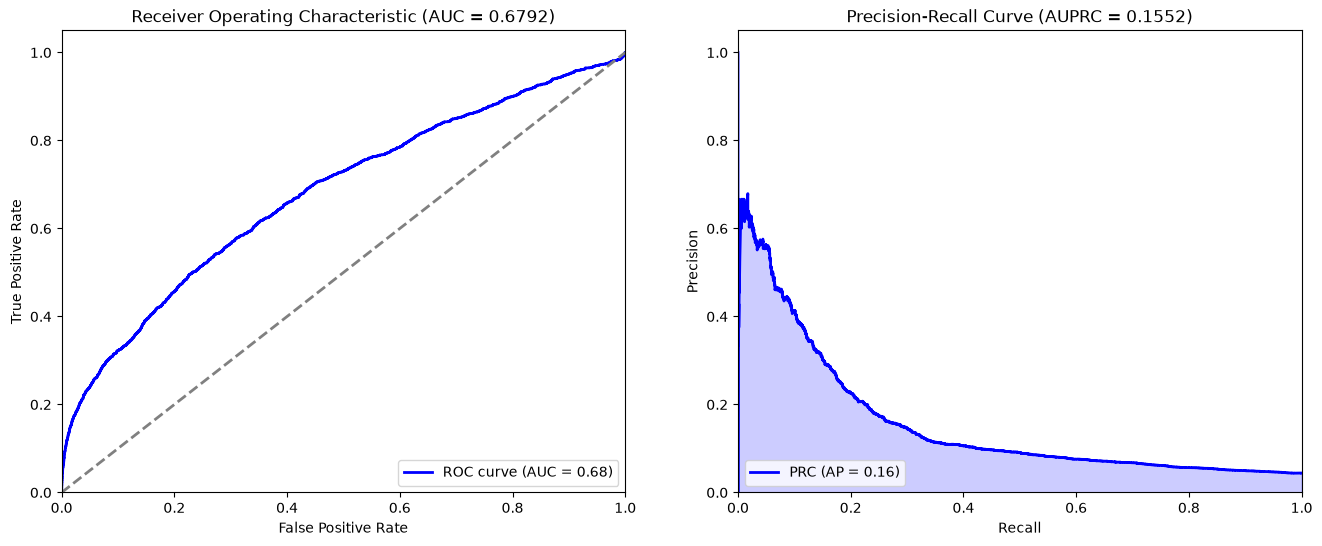

In [24]:
# register model with mlflow
m2v_version = register_model_version(m2v_uri, model_name="med2vec-task3", alias="basic")

# plot ROC-PRC
plots.plot_roc_prc(test.y, m2v_probs)

# Comparative Performance Output

In [25]:
run_names = ["logistic-regression-task3", "random-forest-task3", "xgboost-task3", "mlp-task3", "med2vec-task3"]

def get_run_metrics(experiment_id: str, run_name: str) -> dict:
    """Return the logged params-free metrics of the most recent run with the given name."""
    runs = mlflow.search_runs(
        experiment_ids=[experiment_id],
        filter_string=f"tags.mlflow.runName = '{run_name}'",
        order_by=["attributes.start_time DESC"],
        max_results=1,
    )
    if runs.empty:
        raise RuntimeError(f"No MLflow run found with name {run_name!r}.")
    run_id = runs.iloc[0]["run_id"]
    # latest value of each metric (the MLP logs per-epoch, prefixed metrics)
    return {"model": run_name, **MlflowClient().get_run(run_id).data.metrics}


comparison_df = pl.DataFrame(
    [get_run_metrics(experiment.experiment_id, name) for name in run_names],
    infer_schema_length=None,
)

# clean-up my sloppy MLP metrics conventions
comparison_df = comparison_df.drop([c for c in comparison_df.columns if c.startswith("test_")])
train_cols = [c for c in comparison_df.columns if c.startswith("train_")]
for c in train_cols:
    base = c.removeprefix("train_")
    comparison_df = comparison_df.with_columns(**{
        base: pl.coalesce(pl.col(base), pl.col(c)) if base in comparison_df.columns else pl.col(c)
    })
comparison_df = comparison_df.drop(train_cols)

comparison_df.show()

model,fit_time_seconds,tn,fp,fn,tp,accuracy,precision,recall,specificity,f1,roc_auc,average_precision,threshold,loss
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""logistic-regression-task3""",5.166546,44354.0,64.0,1969.0,89.0,0.956257,0.581699,0.043246,0.998559,0.080507,0.682271,0.153414,null,null
"""random-forest-task3""",38.581207,44367.0,51.0,1984.0,74.0,0.956214,0.592,0.035957,0.998852,0.067797,0.66166,0.144695,null,null
"""xgboost-task3""",1.076661,44302.0,116.0,1956.0,102.0,0.955418,0.46789,0.049563,0.997388,0.089631,0.680047,0.143898,null,null
"""mlp-task3""",134.868906,177392.0,89.0,8336.0,168.0,0.954701,0.653696,0.019755,0.999499,0.038352,0.696384,0.168701,null,null
"""med2vec-task3""",24.545389,30140.0,14278.0,855.0,1203.0,0.674391,0.077708,0.584548,0.678554,0.13718,0.679151,0.155171,0.463163,1.168211
